<div style="text-align:center;background:#d9c9f0; color:#3b2a5c; padding:30px; border-radius:8px">

<h1><b>Regresión Lineal Múltiple</b></h1>
<h3>Predicción de la Esperanza de Vida</h3>
<hr style="border:1px solid #8e72b8; width:60%">
<h4>Integrantes del equipo</h4>

<table style="margin:auto; border:none; color:#3b2a5c; font-size:16px;">
<tr>
<td style="border:none; padding:6px 24px;">Mariana Castrejón Pulido</td>
<td style="border:none; padding:6px 24px;">Pamela Muñoz Villar</td>
<td style="border:none; padding:6px 24px;">Fabricio Condes Ballesteros</td>
</tr>
<tr>
<td style="border:none; padding:6px 24px;">Kevin Scott Rodrigues Moreno</td>
<td style="border:none; padding:6px 24px;">Sergio Yahir Hernández Guerrero</td>
<td style="border:none; padding:6px 24px;">Emmanuel Paduano Flores</td>
</tr>
</table>

</div>

<div style="background:#f1f8f4; color:black; padding:25px 35px; border-left:8px solid #2e7d4f; border-radius:6px; text-align:left;">

<h2 style="color:#2e7d4f; margin-top:0;"><b>ÍNDICE</b></h2>
<hr style="border:1px solid #a5d6b7;">

[<span style="color:#1b5e3b; font-size:19px;"><b>1. Conjunto de datos</b></span>](#1-conjunto-de-datos)

[<span style="color:#1b5e3b; font-size:19px;"><b>2. Importación de librerías</b></span>](#2-importación-de-librerías)

[<span style="color:#1b5e3b; font-size:19px;"><b>3. Preprocesamiento de datos</b></span>](#3-preprocesamiento-de-datos)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[<span style="color:#1b5e3b; font-size:16px;">3.1. Valores nulos</span>](#31-valores-nulos)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[<span style="color:#1b5e3b; font-size:16px;">3.2. Duplicados</span>](#32-duplicados)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[<span style="color:#1b5e3b; font-size:16px;">3.3. Tipos de datos</span>](#33-tipos-de-datos)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[<span style="color:#1b5e3b; font-size:16px;">3.4. Escalado</span>](#34-escalado)

[<span style="color:#1b5e3b; font-size:19px;"><b>4. Modelado: regresión lineal múltiple</b></span>](#4-modelado-regresión-lineal-múltiple)

[<span style="color:#1b5e3b; font-size:19px;"><b>5. Predicciones</b></span>](#5-predicciones)

[<span style="color:#1b5e3b; font-size:19px;"><b>6. Métricas de evaluación</b></span>](#6-métricas-de-evaluación)

[<span style="color:#1b5e3b; font-size:19px;"><b>7. Gráfica de valores reales contra predichos</b></span>](#7-gráfica-de-valores-reales-contra-predichos)

[<span style="color:#1b5e3b; font-size:19px;"><b>8. Predicción para un nuevo paciente</b></span>](#8-predicción-para-un-nuevo-paciente)

[<span style="color:#1b5e3b; font-size:19px;"><b>9. Conclusiones</b></span>](#9-conclusiones)

</div>



<div style="background:#f8c8dc; color:#5a1a33; padding:10px 20px; border-radius:6px">

## 1. Conjunto de datos

</div>

---

El proyecto utiliza el archivo `Life_Expectancy_Data.csv`.


Cada fila es **un país en un año** (2000 a 2015). Tiene **2,938 registros** y **22 columnas**.

### Metadatos (diccionario de datos)

* **y** = lo que queremos predecir (`Life expectancy`).
* **X** = los datos que usamos para predecir.
* Las demás columnas se descartan (el motivo está en la tabla).

| Variable | Significado | Uso en el modelo |
| :--- | :--- | :--- |
| `Country` | País | Descartada (categórica con 193 valores) |
| `Year` | Año de la observación (2000 a 2015) | Descartada (solo identifica el periodo) |
| `Status` | Developed (desarrollado) / Developing (en desarrollo) | **X** (se convierte a 0/1) |
| `Life expectancy` | Esperanza de vida al nacer, en años | **y** (variable dependiente) |
| `Adult Mortality` | Muertes de adultos (15 a 60 años) por cada 1,000 habitantes | **X** |
| `infant deaths` | Muertes infantiles por cada 1,000 habitantes | Descartada (muy correlacionada con `under-five deaths`) |
| `Alcohol` | Consumo de alcohol per cápita (litros de alcohol puro) | **X** |
| `percentage expenditure` | Gasto en salud como % del PIB per cápita | Descartada |
| `Hepatitis B` | % de inmunización contra Hepatitis B (1 año de edad) | Descartada |
| `Measles` | Casos reportados de sarampión por cada 1,000 habitantes | Descartada |
| `BMI` | Índice de masa corporal promedio de la población | **X** |
| `under-five deaths` | Muertes de menores de 5 años por cada 1,000 habitantes | **X** |
| `Polio` | % de inmunización contra polio (1 año de edad) | **X** |
| `Total expenditure` | Gasto público en salud como % del gasto total del gobierno | **X** |
| `Diphtheria` | % de inmunización DTP3 (1 año de edad) | Descartada (correlacionada con `Polio`) |
| `HIV/AIDS` | Muertes por VIH/SIDA por cada 1,000 nacimientos (0 a 4 años) | **X** |
| `GDP` | Producto Interno Bruto per cápita (USD) | **X** |
| `Population` | Población del país | Descartada (muchos faltantes) |
| `thinness 1-19 years` | % de delgadez en personas de 10 a 19 años | Descartada (redundante) |
| `thinness 5-9 years` | % de delgadez en niños de 5 a 9 años | Descartada |
| `Income composition of resources` | Índice de Desarrollo Humano por ingresos (0 a 1) | **X** |
| `Schooling` | Años promedio de escolaridad | **X** |

---

<a id="librerias"></a>

<div style="background:#fff3b0; color:#5c4a00; padding:10px 20px; border-radius:6px">

## 2. Importación de librerías

</div>

---

**Importar librerías** consiste en cargar módulos de código ya escritos para usar sus funciones. Se utiliza la palabra clave `import` al inicio del script, y `from` cuando solo se necesita un módulo o clase específica.

**Librerías utilizadas en este proyecto:**

* `pathlib.Path`: manejo de rutas de archivos.
* `numpy`: operaciones matemáticas y manejo de vectores/matrices (se usa para resolver la regresión).
* `pandas`: manipulación y análisis de datos en tablas (DataFrames).
* `matplotlib.pyplot`: creación de gráficas.

---

In [1]:
from pathlib import Path          
import numpy as np                
import pandas as pd               
import matplotlib.pyplot as plt   

CARPETA = Path.cwd()
RUTA_CSV = CARPETA / "Life Expectancy Data.csv"

datos = pd.read_csv(RUTA_CSV)

datos.columns = datos.columns.str.strip().str.replace(r"\s+", " ", regex=True)

print(f"Registros: {datos.shape[0]} | Columnas: {datos.shape[1]}")
print(datos.head().to_string())



Registros: 2938 | Columnas: 22
       Country  Year      Status  Life expectancy  Adult Mortality  infant deaths  Alcohol  percentage expenditure  Hepatitis B  Measles   BMI  under-five deaths  Polio  Total expenditure  Diphtheria  HIV/AIDS         GDP  Population  thinness 1-19 years  thinness 5-9 years  Income composition of resources  Schooling
0  Afghanistan  2015  Developing             65.0            263.0             62     0.01               71.279624         65.0     1154  19.1                 83    6.0               8.16        65.0       0.1  584.259210  33736494.0                 17.2                17.3                            0.479       10.1
1  Afghanistan  2014  Developing             59.9            271.0             64     0.01               73.523582         62.0      492  18.6                 86   58.0               8.18        62.0       0.1  612.696514    327582.0                 17.5                17.5                            0.476       10.0
2  Afghanist

<div style="background:#d9c9f0; color:#3b2a5c; padding:10px 20px; border-radius:6px">

## 3. Preprocesamiento de datos

</div>

---

Los datos reales vienen "sucios", así que antes de entrenar hay que limpiarlos. Primero se define qué variable se predice ($y$) y con qué se predice ($X$), y se conservan solo las **12 columnas del modelo** (1 $y$ y 11 $X$).

---

In [2]:
VAR_Y = "Life expectancy"                       # lo que se predice
VARS_X = ["Status", "Adult Mortality", "Alcohol", "BMI", "under-five deaths", "Polio",
          "Total expenditure", "HIV/AIDS", "GDP", "Income composition of resources",
          "Schooling"]                          # con lo que se predice

# Nos quedamos solo con las 12 columnas del modelo (1 y + 11 X).
df = datos[[VAR_Y] + VARS_X].copy()

### 3.1. Valores nulos

Un nulo es un dato que falta, y el modelo matemático no puede usar celdas vacías. Hay nulos en 9 columnas, sobre todo en `GDP` (448), `Total expenditure` (226), `Alcohol` (194), `Income composition of resources` (167) y `Schooling` (163).

* Si falta la $y$ (la respuesta), esa fila no sirve para aprender: se **elimina** (10 filas).
* Si falta una $X$, no se elimina la fila, porque se perderían muchos datos: se **rellena con la mediana** de esa columna. Se usa la mediana y no el promedio porque no la afectan los valores extremos.

In [3]:
print("Nulos por columna:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Si falta la y (la respuesta), esa fila no sirve para aprender: se elimina.
df = df.dropna(subset=[VAR_Y])

# Si falta una X, NO eliminamos la fila (perderíamos muchos datos):
# la rellenamos con la MEDIANA de esa columna (el valor "de en medio").
# Usamos la mediana y no el promedio porque no la afectan los valores extremos.
medianas = df.drop(columns=["Status"]).median(numeric_only=True)
df = df.fillna(medianas)
print("Nulos restantes:", int(df.isnull().sum().sum()))

Nulos por columna:
Life expectancy                     10
Adult Mortality                     10
Alcohol                            194
BMI                                 34
Polio                               19
Total expenditure                  226
GDP                                448
Income composition of resources    167
Schooling                          163
dtype: int64
Nulos restantes: 0


### 3.2. Duplicados

Las filas idénticas repetidas harían que el modelo les diera más peso del que merecen. En este conjunto de datos no se encontraron duplicados.

In [4]:
repetidos = int(df.duplicated().sum())
df = df.drop_duplicates()
print(f"Duplicados eliminados: {repetidos}")

Duplicados eliminados: 0


### 3.3. Tipos de datos

La regresión solo trabaja con números. `Status` es texto, así que se convierte: **Developed = 1** y **Developing = 0**. Después se confirma que todas las columnas sean numéricas.

In [5]:

df["Status"] = df["Status"].map({"Developed": 1, "Developing": 0})
df = df.apply(pd.to_numeric, errors="coerce").dropna()
df.info()
print(df.describe().T[["mean", "std", "min", "max"]].to_string())

<class 'pandas.DataFrame'>
Index: 2928 entries, 0 to 2937
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Life expectancy                  2928 non-null   float64
 1   Status                           2928 non-null   int64  
 2   Adult Mortality                  2928 non-null   float64
 3   Alcohol                          2928 non-null   float64
 4   BMI                              2928 non-null   float64
 5   under-five deaths                2928 non-null   int64  
 6   Polio                            2928 non-null   float64
 7   Total expenditure                2928 non-null   float64
 8   HIV/AIDS                         2928 non-null   float64
 9   GDP                              2928 non-null   float64
 10  Income composition of resources  2928 non-null   float64
 11  Schooling                        2928 non-null   float64
dtypes: float64(10), int64(2)
memory usag

### 3.4. Escalado

**Paso A: separar los datos.**

* **80 % para entrenar:** el modelo aprende con estos datos.
* **20 % para probar:** países que el modelo nunca vio, que sirven para medir qué tan bien predice.

**Paso B: escalar.** Las variables tienen escalas muy distintas (`GDP` en miles, `Income composition of resources` de 0 a 1). La **estandarización** las deja con media 0 y desviación estándar 1:

$$z = \frac{x - \bar{x}}{s}$$

Así todas quedan en una escala comparable y los coeficientes se pueden comparar entre sí. La media y la desviación se calculan **solo con el entrenamiento**, para que la prueba siga "ciega".

In [6]:
# PASO A: separar los datos.
#   80 % para ENTRENAR (el modelo aprende aquí).
#   20 % para PROBAR (países que el modelo nunca vio; sirven para medir qué tan bien predice).
rng = np.random.default_rng(42)           # semilla fija: siempre se separa igual
idx = rng.permutation(len(df))
corte = int(0.8 * len(df))
train, test = df.iloc[idx[:corte]], df.iloc[idx[corte:]]

X_train, y_train = train[VARS_X].to_numpy(float), train[VAR_Y].to_numpy(float)
X_test, y_test = test[VARS_X].to_numpy(float), test[VAR_Y].to_numpy(float)

# PASO B: escalar.
#   Estandarizar = (valor - media) / desviación estándar.
#   La media y la desviación se calculan SOLO con el entrenamiento (así la prueba sigue "ciega").
mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
sigma[sigma == 0] = 1.0
X_train_s = (X_train - mu) / sigma
X_test_s = (X_test - mu) / sigma
print(f"Entrenamiento: {len(train)} registros | Prueba: {len(test)} registros")

Entrenamiento: 2342 registros | Prueba: 586 registros


<div style="background:#c5e1f5; color:#1f3d5c; padding:10px 20px; border-radius:6px">

## 4. Modelado: regresión lineal múltiple

</div>

---

La **regresión lineal múltiple** predice una variable $y$ a partir de varias variables independientes. Con las 11 variables escaladas del modelo, la ecuación es:

$$y = b_0 + b_1 Z_1 + b_2 Z_2 + \dots + b_{11} Z_{11}$$

| Símbolo | Significado |
| :--- | :--- |
| $y$ | Esperanza de vida (variable a predecir) |
| $Z_1$ a $Z_{11}$ | Variables independientes escaladas, en el orden de `VARS_X` |
| $b_0$ | Intercepto (esperanza de vida promedio cuando todas las variables están en su media) |
| $b_1$ a $b_{11}$ | Coeficientes: años de esperanza de vida que cambian por cada desviación estándar que aumenta la variable |

Los coeficientes se calculan con el **método de mínimos cuadrados**, que minimiza la suma de los errores al cuadrado:

$$\beta = (X^T X)^{-1} X^T y$$

Se agrega una **columna de unos** a $X$ para calcular también el intercepto $b_0$, y `np.linalg.lstsq()` resuelve el cálculo. Se ordena la tabla por importancia: mientras más lejos de 0 esté un coeficiente, más influye esa variable. Un signo positivo indica que a más valor, más esperanza de vida; uno negativo, lo contrario.

---

In [7]:
# Buscamos los coeficientes b0...b11 que hagan la suma de errores al cuadrado lo más
# pequeña posible (método de MÍNIMOS CUADRADOS).
# Se agrega una columna de unos a X para que el cálculo también encuentre b0 (el intercepto).
A_train = np.column_stack((np.ones(len(X_train_s)), X_train_s))
coef, *_ = np.linalg.lstsq(A_train, y_train, rcond=None)   # aquí se "aprende" el modelo

# Mostramos los coeficientes: mientras más lejos de 0, más influye esa variable.
# Signo positivo = a más valor, más esperanza de vida. Negativo = al revés.
tabla_coef = pd.DataFrame({"Variable": ["Intercepto"] + VARS_X, "Coeficiente (escalado)": coef})
tabla_coef["|Importancia|"] = tabla_coef["Coeficiente (escalado)"].abs()
print(tabla_coef.sort_values("|Importancia|", ascending=False).to_string(index=False))

                       Variable  Coeficiente (escalado)  |Importancia|
                     Intercepto               69.392784      69.392784
                Adult Mortality               -2.640225       2.640225
                       HIV/AIDS               -2.385138       2.385138
                      Schooling                2.285146       2.285146
Income composition of resources                1.322646       1.322646
                          Polio                1.220773       1.220773
                            BMI                1.042906       1.042906
                         Status                0.578515       0.578515
                            GDP                0.509100       0.509100
              under-five deaths               -0.451534       0.451534
                        Alcohol                0.228841       0.228841
              Total expenditure                0.192382       0.192382


<a id="predicciones"></a>

<div style="background:#ffd9b8; color:#6b3a10; padding:10px 20px; border-radius:6px">

## 5. Predicciones

</div>

---

Con los coeficientes calculados, se obtienen las **predicciones** multiplicando la matriz $X$ por el vector de coeficientes:

$$\hat{y} = X \cdot \beta$$

Después se calcula el **error** de cada registro como la diferencia entre el valor real y el predicho:

$$Error = y - \hat{y}$$

---

In [8]:
# Aplicamos la fórmula a los países de prueba y comparamos con lo que realmente pasó.
A_test = np.column_stack((np.ones(len(X_test_s)), X_test_s))
y_pred_train = A_train @ coef
y_pred = A_test @ coef

resultados = test[[VAR_Y]].copy()
resultados["Predicha"] = y_pred
resultados["Error"] = resultados[VAR_Y] - resultados["Predicha"]   # real - predicho
print(resultados.head(10).round(2).to_string())

      Life expectancy  Predicha  Error
194              71.0     67.21   3.79
2801             78.2     77.95   0.25
1070             69.4     70.26  -0.86
163              74.9     73.67   1.23
2403             53.8     49.66   4.14
2209             72.0     66.62   5.38
1759             72.0     69.02   2.98
417              59.1     63.52  -4.42
726              57.4     64.46  -7.06
1550             78.6     80.39  -1.79


<div style="background:#e2efb5; color:#3d4d12; padding:10px 20px; border-radius:6px">

## 6. Métricas de evaluación

</div>

---

Las **métricas de evaluación** indican qué tan bien se ajusta el modelo a los datos. Se calculan con los datos de entrenamiento y con los de prueba. Si ambos resultados son parecidos, el modelo generaliza bien (no solo "memorizó").

### 🔹 R² (coeficiente de determinación)

$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}}$$

Proporción de la variación de $y$ que explica el modelo. Mientras más cercano a 1, mejor.

### 🔹 MAE (error absoluto medio)

$$MAE = \frac{1}{n}\sum \lvert y - \hat{y} \rvert$$

Error promedio en las mismas unidades de $y$ (en este proyecto, años).

### 🔹 RMSE (raíz del error cuadrático medio)

$$RMSE = \sqrt{\frac{1}{n}\sum (y - \hat{y})^2}$$

Error promedio que penaliza más los errores grandes, también en años.

Donde $SS_{res} = \sum (y - \hat{y})^2$ y $SS_{tot} = \sum (y - \bar{y})^2$.

---

In [9]:
# R²   : qué proporción de la variación explica el modelo (1 = perfecto, 0 = inútil).
# MAE  : error promedio, en años.
# RMSE : parecido al MAE pero castiga más los errores grandes, también en años.
def metricas(y, yhat):
    ss_res, ss_tot = np.sum((y - yhat) ** 2), np.sum((y - y.mean()) ** 2)
    return {"R²": 1 - ss_res / ss_tot,
            "MAE": np.mean(np.abs(y - yhat)),
            "RMSE": np.sqrt(np.mean((y - yhat) ** 2))}

m_train, m_test = metricas(y_train, y_pred_train), metricas(y_test, y_pred)
print(pd.DataFrame({"Entrenamiento": m_train, "Prueba": m_test}).round(4))
# Si ambas columnas son parecidas, el modelo generaliza bien (no solo "memorizó").

      Entrenamiento  Prueba
R²           0.8033  0.7993
MAE          3.0993  3.2764
RMSE         4.1845  4.4062


<a id="grafica"></a>

<div style="background:#c9ecd9; color:#1f4d37; padding:10px 20px; border-radius:6px">

## 7. Gráfica de valores reales contra predichos

</div>

---

La gráfica compara la tasa de supervivencia **real** (eje X) contra la **predicha** (eje Y). Cada punto es un registro, y la **línea punteada** representa la predicción perfecta: mientras más cerca estén los puntos de ella, mejor es el modelo.

---

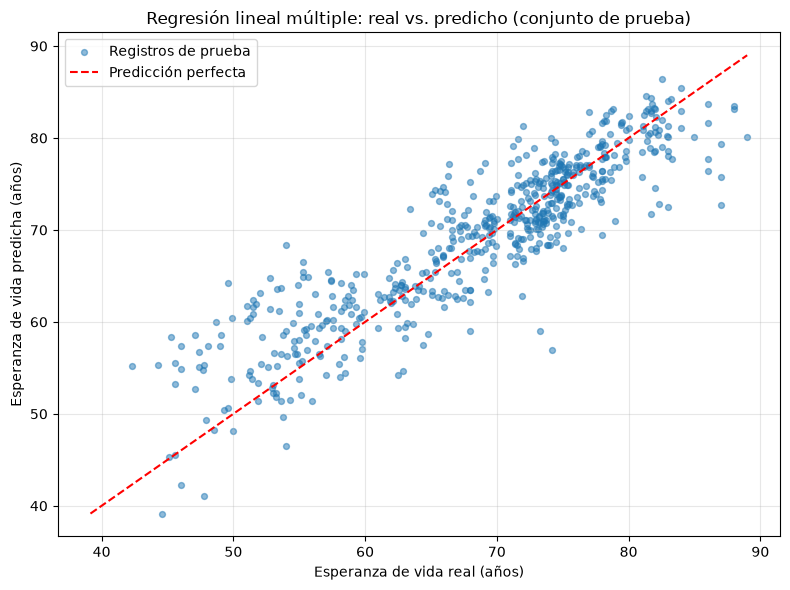

In [10]:
# Cada punto es un país de prueba. Si el modelo fuera perfecto, todos caerían sobre la línea roja.
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, s=18, alpha=0.5, label="Registros de prueba")
lim = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lim, lim, "--", color="red", label="Predicción perfecta")
plt.xlabel("Esperanza de vida real (años)")
plt.ylabel("Esperanza de vida predicha (años)")
plt.title("Regresión lineal múltiple: real vs. predicho (conjunto de prueba)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(CARPETA / "grafica_real_vs_predicho.png", dpi=150)
plt.show()

<div style="background:#f9c9c4; color:#6b1f1a; padding:10px 20px; border-radius:6px">

## 8. Predicción para un nuevo registro

</div>

---

El usuario escribe los 11 valores de un país y el programa valida cada uno de dos formas:

* **Validación obligatoria:** el valor debe ser un número dentro de un rango lógico (un porcentaje no puede ser 150). Si no cumple, se vuelve a pedir.
* **Aviso:** si el valor es posible pero está fuera de lo que el modelo vio al entrenar, se avisa que la predicción sería poco confiable (extrapolación).

Los valores nuevos se escalan con la media y la desviación del entrenamiento antes de aplicar la fórmula.

**Ejemplo:** un país en desarrollo (`Status` = 0) con `Adult Mortality` = 150, `Alcohol` = 3, `BMI` = 50, `under-five deaths` = 20, `Polio` = 90, `Total expenditure` = 6, `HIV/AIDS` = 0.1, `GDP` = 1800, `Income composition of resources` = 0.7 y `Schooling` = 13 tiene una esperanza de vida estimada de **72.1 años**.

---

In [11]:

MODO_INTERACTIVO = False

# (nombre en el modelo): (texto para el usuario, mínimo lógico, máximo lógico)
LIMITES = {
    "Adult Mortality": ("Mortalidad adulta (muertes por cada 1,000 adultos)", 0, 1000),
    "Alcohol": ("Consumo de alcohol per cápita (litros)", 0, 30),
    "BMI": ("Índice de masa corporal promedio", 10, 90),
    "under-five deaths": ("Muertes de menores de 5 años (por cada 1,000)", 0, 1000),
    "Polio": ("Inmunización contra polio (%)", 0, 100),
    "Total expenditure": ("Gasto público en salud (% del gasto del gobierno)", 0, 100),
    "HIV/AIDS": ("Muertes por VIH/SIDA (por cada 1,000 nacimientos)", 0, 100),
    "GDP": ("PIB per cápita (USD)", 0, 500000),
    "Income composition of resources": ("Índice de ingresos (entre 0 y 1)", 0, 1),
    "Schooling": ("Años promedio de escolaridad", 0, 25),
}
# Rango observado en los datos de entrenamiento (para el aviso de extrapolación).
RANGO_OBSERVADO = {v: (train[v].min(), train[v].max()) for v in VARS_X}

# País de ejemplo (se usa cuando MODO_INTERACTIVO = False).
PAIS_EJEMPLO = {
    "Status": 0,
    "Adult Mortality": 150,
    "Alcohol": 3,
    "BMI": 50,
    "under-five deaths": 20,
    "Polio": 90,
    "Total expenditure": 6,
    "HIV/AIDS": 0.1,
    "GDP": 1800,
    "Income composition of resources": 0.7,
    "Schooling": 13,
}


def pedir_numero(nombre, texto, minimo, maximo):
    """Pide un número hasta que sea válido. Acepta coma o punto decimal."""
    while True:
        entrada = input(f"{texto} [{minimo} a {maximo}]: ").strip().replace(",", ".")
        try:
            valor = float(entrada)
        except ValueError:
            print("  ✗ Escribe solo un número (ejemplo: 12.5).")
            continue
        if not np.isfinite(valor):
            print("  ✗ Ese valor no es válido.")
            continue
        if not (minimo <= valor <= maximo):
            print(f"  ✗ El valor debe estar entre {minimo} y {maximo}.")
            continue
        lo, hi = RANGO_OBSERVADO[nombre]
        if not (lo <= valor <= hi):
            print(f"  ⚠ Aviso: el modelo solo vio valores entre {lo:.2f} y {hi:.2f}; "
                  f"la predicción podría ser menos confiable.")
        return valor


def pedir_estatus():
    """Pide si el país es desarrollado (1) o en desarrollo (0)."""
    while True:
        entrada = input("Estatus del país [1 = desarrollado, 0 = en desarrollo]: ").strip()
        if entrada in ("0", "1"):
            return int(entrada)
        print("  ✗ Escribe 1 (desarrollado) o 0 (en desarrollo).")


def predecir(registro: dict) -> float:
    """Aplica la fórmula del modelo a un país.
    Pasos: ordenar valores -> escalar con la media/desviación del entrenamiento ->
    multiplicar por los coeficientes y sumar el intercepto."""
    x = np.array([[registro[v] for v in VARS_X]], dtype=float)
    x_escalado = (x - mu) / sigma
    return float(np.concatenate(([1.0], x_escalado[0])) @ coef)


def mostrar_resultado(pais):
    estimacion = predecir(pais)
    print(f"\n>>> Esperanza de vida estimada: {estimacion:.1f} años")
    print(f"    (el modelo se equivoca en promedio ±{m_test['MAE']:.1f} años en los datos de prueba)")


if MODO_INTERACTIVO:
    print("\nPREDICCIÓN PARA UN NUEVO PAÍS")
    while True:
        nuevo_pais = {"Status": pedir_estatus()}
        for variable, (texto, minimo, maximo) in LIMITES.items():
            nuevo_pais[variable] = pedir_numero(variable, texto, minimo, maximo)

        mostrar_resultado(nuevo_pais)

        if input("\n¿Predecir otro país? (s/n): ").strip().lower() != "s":
            break
else:
    print("\nPREDICCIÓN PARA UN NUEVO PAÍS (ejemplo)")
    for variable, valor in PAIS_EJEMPLO.items():
        print(f"  {variable}: {valor}")
    mostrar_resultado(PAIS_EJEMPLO)



PREDICCIÓN PARA UN NUEVO PAÍS (ejemplo)
  Status: 0
  Adult Mortality: 150
  Alcohol: 3
  BMI: 50
  under-five deaths: 20
  Polio: 90
  Total expenditure: 6
  HIV/AIDS: 0.1
  GDP: 1800
  Income composition of resources: 0.7
  Schooling: 13

>>> Esperanza de vida estimada: 72.1 años
    (el modelo se equivoca en promedio ±3.3 años en los datos de prueba)


<div style="background:#bfe3e0; color:#1f4d4a; padding:10px 20px; border-radius:6px">

## 9. Conclusiones

</div>

---

* Se construyó un modelo de regresión lineal múltiple que estima la **esperanza de vida** de un país a partir de 11 variables de salud, economía y educación.
* De los 2,938 registros se eliminaron 10 que no tenían esperanza de vida, y los datos faltantes de las variables independientes se rellenaron con la mediana. No había duplicados, y se trabajó con **2,928 registros**.
* Los datos se separaron en **2,342 para entrenar** y **586 para probar**.
* En los datos de prueba el modelo obtuvo un **R² de 0.80**, un **MAE de 3.28 años** y un **RMSE de 4.41 años**. Como los resultados de entrenamiento son muy parecidos (R² de 0.80), el modelo generaliza bien y no solo "memorizó".
* Las variables que más influyen (ya escaladas) son `Adult Mortality` (−2.64), `HIV/AIDS` (−2.39), `Schooling` (+2.29) e `Income composition of resources` (+1.32). Más escolaridad e ingresos se asocian con mayor esperanza de vida; más mortalidad adulta y más muertes por VIH, con menor esperanza de vida.
* Estas relaciones son asociaciones entre variables, no demuestran causa y efecto.
* Cada país aparece varias años en los datos, y la separación fue aleatoria, así que un mismo país puede estar en entrenamiento y en prueba. Por eso las métricas pueden ser algo optimistas respecto a países completamente nuevos.

---